In [20]:
import json
import ast
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
pd.set_option("display.max_columns", None)

In [2]:
recipes = pd.read_csv("data/pp_recipes.csv")
reviews = pd.read_csv("data/pp_reviews.csv")
members = pd.read_csv("data/pp_members.csv")

C:\Users\atariq25\AppData\Local\Temp\ipykernel_27368\4216538261.py:1: DtypeWarning: Columns (35: ingredient_food_kg_urls, 36: ingredient_food_kg_names) have mixed types. Specify dtype option on import or set low_memory=False.
  recipes = pd.read_csv("data/pp_recipes.csv")
C:\Users\atariq25\AppData\Local\Temp\ipykernel_27368\4216538261.py:2: DtypeWarning: Columns (4: text, 8: review_url, 9: member_url) have mixed types. Specify dtype option on import or set low_memory=False.
  reviews = pd.read_csv("data/pp_reviews.csv")


### Shapes and columns

In [7]:
for name, df in [("recipes", recipes), ("reviews", reviews), ("members", members)]:
    print(f"\n=== {name} ===")
    print("shape:", df.shape)
    print("columns:", df.columns.tolist())
    print("Data types and other info:",df.info())


=== recipes ===
shape: (507335, 37)
columns: ['Unnamed: 0', 'recipe_id', 'title', 'description', 'author_id', 'duration', 'directions', 'ingredients', 'serves', 'last_changed_date', 'food_kg_locator', 'recipe_url', 'tags', 'new_recipe_id', 'new_author_id', 'average_rating', 'number_of_ratings', 'servingsPerRecipe', 'servingSize [g]', 'calories [cal]', 'caloriesFromFat [cal]', 'totalFat [g]', 'saturatedFat [g]', 'cholesterol [mg]', 'sodium [mg]', 'totalCarbohydrate [g]', 'dietaryFiber [g]', 'sugars [g]', 'protein [g]', 'direction_size', 'ingredients_sizes', 'who_score', 'fsa_score', 'nutri_score', 'normalization_comment', 'ingredient_food_kg_urls', 'ingredient_food_kg_names']
<class 'pandas.DataFrame'>
RangeIndex: 507335 entries, 0 to 507334
Data columns (total 37 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Unnamed: 0                507335 non-null  int64  
 1   recipe_id                 507335 non-null 

### Dataframes

In [4]:
recipes.head(2)

,Unnamed: 0,recipe_id,title,description,author_id,duration,directions,ingredients,serves,last_changed_date,food_kg_locator,recipe_url,tags,new_recipe_id,new_author_id,average_rating,number_of_ratings,servingsPerRecipe,servingSize [g],calories [cal],caloriesFromFat [cal],totalFat [g],saturatedFat [g],cholesterol [mg],sodium [mg],totalCarbohydrate [g],dietaryFiber [g],sugars [g],protein [g],direction_size,ingredients_sizes,who_score,fsa_score,nutri_score,normalization_comment,ingredient_food_kg_urls,ingredient_food_kg_names
0,0,447642,Cranberry-Orange Caramel Corn,"Taken from Beter Homes and Gardens, November 2...",409184,40.0,['Preheat oven to 275 degrees. In a very large...,"{'': [('popcorn, popped', '12 time(s) cups ')...",20,2011-01-29,http://idea.rpi.edu/heals/kb/recipe/5e6ae80d-C...,https://www.food.com/recipe/cranberry-orange-c...,NaN,0,4589,0.0,0,20,30.0,97.2,57.0,6.4,3.0,12.2,73.8,9.9,0.7,6.9,0.8,9,9,0.168254,0.000,0.00,NaN,['http://idea.rpi.edu/heals/kb/ingredientname/...,"['baking soda', 'brown sugar', 'butter', 'corn..."
1,1,53662,Cocktail De Camarones,I ordered shrimp cocktail at a Mexican restaur...,64251,20.0,"['After you chop the tomatoes, onions and cila...",{'': [('shelled and cooked shrimp (50-60 count...,2-4,2009-06-03,http://idea.rpi.edu/heals/kb/recipe/d6b47db2-C...,https://www.food.com/recipe/cocktail-de-camaro...,"['30-minutes-or-less', 'time-to-make', 'course...",1,142553,5.0,5,2,303.0,427.3,158.0,17.6,2.9,442.0,526.3,17.8,9.4,6.3,51.3,7,10,0.335455,0.625,0.25,NaN,['http://idea.rpi.edu/heals/kb/ingredientname/...,"['avocado', 'cilantro', 'cooked shrimp', 'garl..."


In [5]:
reviews.head(2)

,Unnamed: 0,member_id,recipe_id,rating,text,likes,last_modified_date,review_id,review_url,member_url,new_member_id,new_recipe_id
0,0,192799,96347,5.0,"I've never made ham & beans before, but I've a...",0.0,2005-05-02,171462.0,https://www.food.com/recipe/crock-pot-ham-and-...,https://www.food.com/user/192799,0,274797
1,1,394617,37139,2.5,Great curry. Will make again. I was thinking...,0.0,2012-03-25,1296592.0,https://www.food.com/recipe/curry-chicken-with...,https://www.food.com/user/394617,1,274880


In [6]:
members.head(2)

,Unnamed: 0,member_id,member_url,member_name,member_description,member_status,member_avg_rating,member_map_pin,member_joined,follows_count,follow_me_count,avatar_url,new_member_id
0,0,911346,https://www.food.com/user/911346,jerome.a.fried,NaN,NaN,NaN,NaN,2008-08-01,0,0,https://geniuskitchen.sndimg.com/gk/img/avatar...,131066
1,1,2000090836,https://www.food.com/user/2000090836,Kimberly L.,NaN,NaN,NaN,NaN,2015-03-01,0,0,https://geniuskitchen.sndimg.com/gk/img/avatar...,131068


### Missingness

In [8]:
datasets = {
    "Members": members,
    "Recipes": recipes,
    "Reviews": reviews
}

for name, df in datasets.items():
    print("=" * 70)
    print(f"{name} - Data Types")
    print("=" * 70)
    display(
        pd.DataFrame({
            "column": df.columns,
            "dtype": df.dtypes.astype(str).values,
            "non_null": df.notna().sum().values,
            "missing": df.isna().sum().values
        })
    )

Members - Data Types


,column,dtype,non_null,missing
0,Unnamed: 0,int64,299583,0
1,member_id,int64,299583,0
2,member_url,str,299583,0
3,member_name,str,299583,0
4,member_description,str,39315,260268
5,member_status,str,69159,230424
6,member_avg_rating,float64,30784,268799
7,member_map_pin,str,32398,267185
8,member_joined,str,299583,0
9,follows_count,int64,299583,0


Recipes - Data Types


,column,dtype,non_null,missing
0,Unnamed: 0,int64,507335,0
1,recipe_id,int64,507335,0
2,title,str,507335,0
3,description,str,497228,10107
4,author_id,int64,507335,0
5,duration,float64,499997,7338
6,directions,str,507335,0
7,ingredients,str,507333,2
8,serves,str,435937,71398
9,last_changed_date,str,507335,0


Reviews - Data Types


,column,dtype,non_null,missing
0,Unnamed: 0,int64,1916424,0
1,member_id,int64,1916424,0
2,recipe_id,int64,1916424,0
3,rating,float64,1916424,0
4,text,str,1409706,506718
5,likes,float64,1409914,506510
6,last_modified_date,str,1916424,0
7,review_id,float64,1409914,506510
8,review_url,str,1409914,506510
9,member_url,str,1409914,506510


In [9]:
def missing_value_report(df):
    report = pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percent": df.isna().mean() * 100,
        "non_missing_count": df.notna().sum()
    })

    return report.sort_values("missing_percent", ascending=False)


for name, df in datasets.items():
    print("=" * 70)
    print(f"{name} - Missing Values")
    print("=" * 70)
    
    display(missing_value_report(df))

Members - Missing Values


,missing_count,missing_percent,non_missing_count
member_avg_rating,268799,89.724384,30784
member_map_pin,267185,89.185635,32398
member_description,260268,86.876759,39315
member_status,230424,76.914912,69159
Unnamed: 0,0,0.000000,299583
member_name,0,0.000000,299583
member_url,0,0.000000,299583
member_id,0,0.000000,299583
member_joined,0,0.000000,299583
follows_count,0,0.000000,299583


Recipes - Missing Values


,missing_count,missing_percent,non_missing_count
normalization_comment,492958,97.166172,14377
tags,276686,54.537140,230649
ingredient_food_kg_urls,85085,16.770970,422250
ingredient_food_kg_names,85085,16.770970,422250
serves,71398,14.073147,435937
fsa_score,15504,3.055969,491831
description,10107,1.992175,497228
duration,7338,1.446382,499997
who_score,1127,0.222141,506208
ingredients,2,0.000394,507333


Reviews - Missing Values


,missing_count,missing_percent,non_missing_count
text,506718,26.440809,1409706
review_url,506510,26.429955,1409914
likes,506510,26.429955,1409914
review_id,506510,26.429955,1409914
member_url,506510,26.429955,1409914
recipe_id,0,0.000000,1916424
member_id,0,0.000000,1916424
Unnamed: 0,0,0.000000,1916424
rating,0,0.000000,1916424
last_modified_date,0,0.000000,1916424


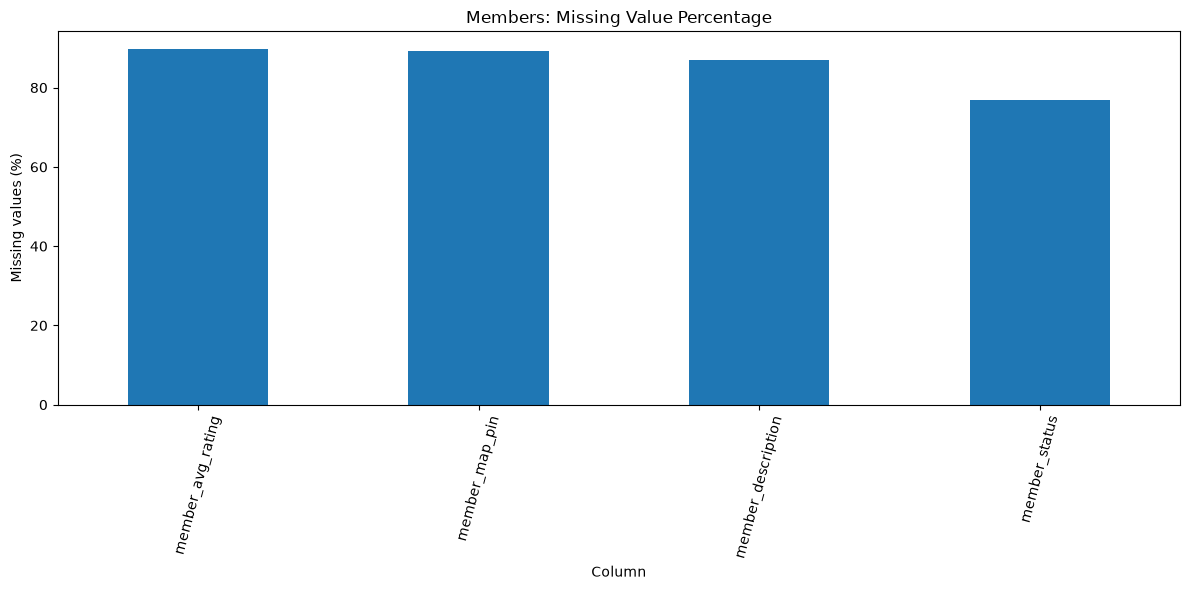

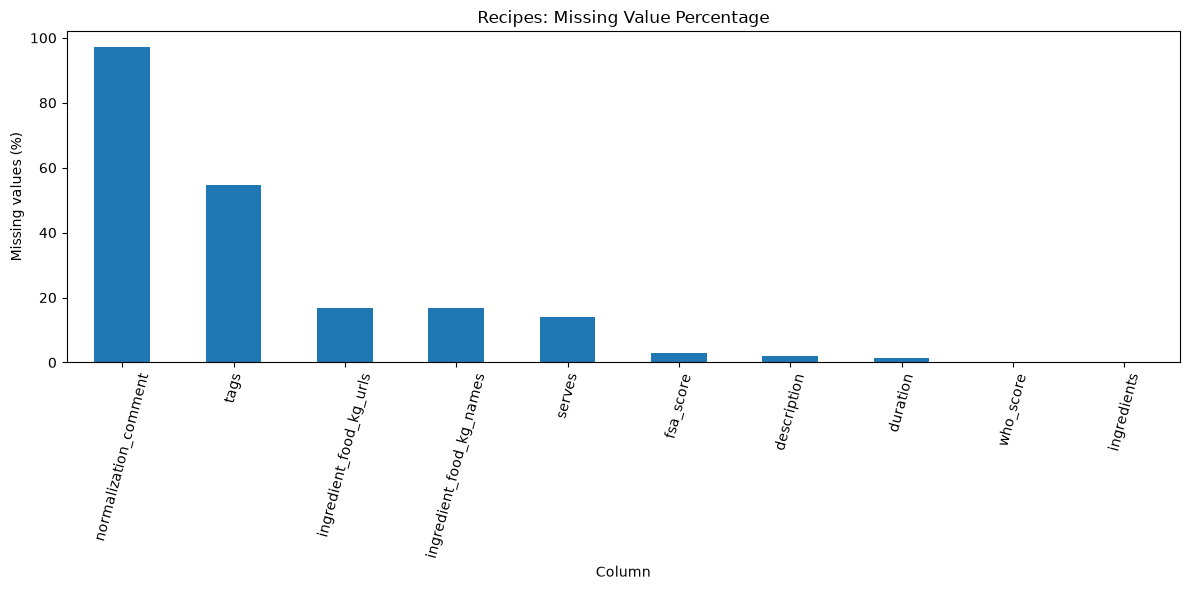

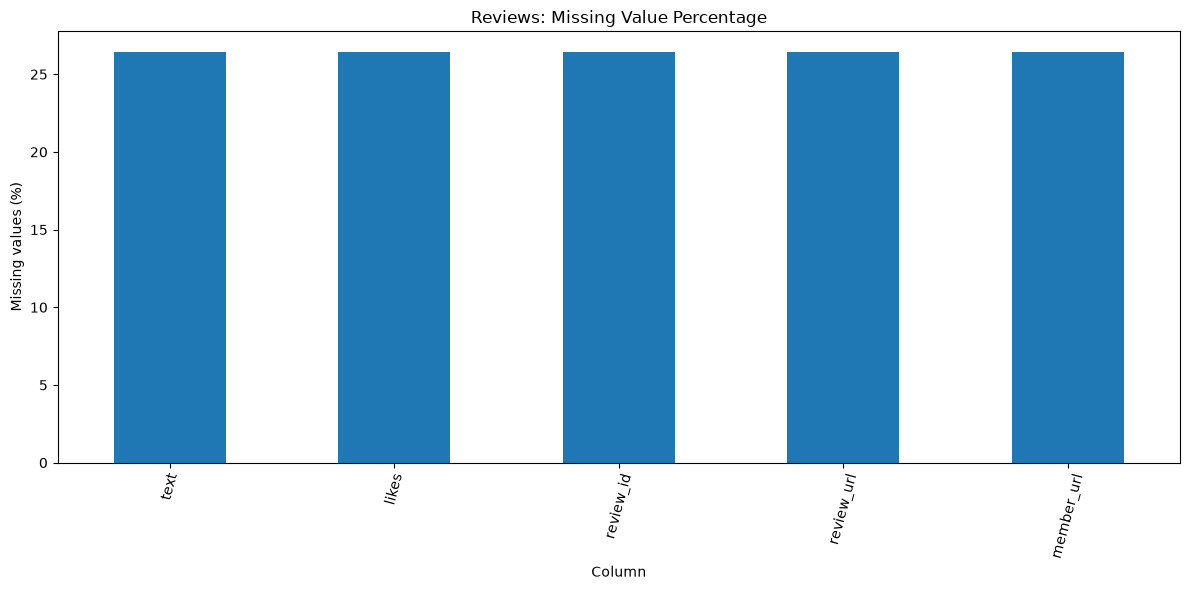

In [11]:
# Visualize missing values

for name, df in datasets.items():
    missing = df.isna().mean() * 100
    missing = missing[missing > 0].sort_values(ascending=False)

    if len(missing) == 0:
        print(f"{name}: No missing values.")
        continue

    plt.figure(figsize=(12, 6))
    missing.plot(kind="bar")
    plt.ylabel("Missing values (%)")
    plt.xlabel("Column")
    plt.title(f"{name}: Missing Value Percentage")
    plt.xticks(rotation=75)
    plt.tight_layout()
    plt.show()

### Duplicate audit

In [12]:
for name, df in datasets.items():
    print("=" * 70)
    print(name)
    print("=" * 70)
    
    print("Duplicate rows:", df.duplicated().sum())
    print("Duplicate percentage:",
          f"{df.duplicated().mean() * 100:.4f}%")
    print()

Members
Duplicate rows: 0
Duplicate percentage: 0.0000%

Recipes
Duplicate rows: 0
Duplicate percentage: 0.0000%

Reviews
Duplicate rows: 0
Duplicate percentage: 0.0000%



### ID audit

In [13]:
for name, df in datasets.items():
    print("=" * 70)
    print(name)
    print("=" * 70)
    
    id_columns = [
        col for col in df.columns
        if "id" in col.lower()
    ]
    
    print("Possible ID columns:")
    
    for col in id_columns:
        print(
            f"{col}: "
            f"{df[col].nunique(dropna=True):,} unique values, "
            f"{df[col].isna().sum():,} missing"
        )

Members
Possible ID columns:
member_id: 299,583 unique values, 0 missing
new_member_id: 299,583 unique values, 0 missing
Recipes
Possible ID columns:
recipe_id: 507,335 unique values, 0 missing
author_id: 54,667 unique values, 0 missing
new_recipe_id: 507,335 unique values, 0 missing
new_author_id: 54,667 unique values, 0 missing
Reviews
Possible ID columns:
member_id: 302,412 unique values, 0 missing
recipe_id: 507,335 unique values, 0 missing
review_id: 1,409,914 unique values, 506,510 missing
new_member_id: 302,412 unique values, 0 missing
new_recipe_id: 507,335 unique values, 0 missing


In [14]:
# Check duplicated values in important ID columns

for col in ["new_member_id", "new_recipe_id"]:
    if col in members.columns:
        print(f"Members: {col}")
        print("Rows:", len(members))
        print("Unique:", members[col].nunique())
        print("Duplicates:", members[col].duplicated().sum())
        print()

    if col in recipes.columns:
        print(f"Recipes: {col}")
        print("Rows:", len(recipes))
        print("Unique:", recipes[col].nunique())
        print("Duplicates:", recipes[col].duplicated().sum())
        print()

    if col in reviews.columns:
        print(f"Reviews: {col}")
        print("Rows:", len(reviews))
        print("Unique:", reviews[col].nunique())
        print("Duplicates:", reviews[col].duplicated().sum())
        print()

Members: new_member_id
Rows: 299583
Unique: 299583
Duplicates: 0

Reviews: new_member_id
Rows: 1916424
Unique: 302412
Duplicates: 1614012

Recipes: new_recipe_id
Rows: 507335
Unique: 507335
Duplicates: 0

Reviews: new_recipe_id
Rows: 1916424
Unique: 507335
Duplicates: 1409089



### Members dataset audit

In [15]:
print("MEMBERS DATASET")
print("=" * 70)

print(f"Number of members: {len(members):,}")

if "new_member_id" in members.columns:
    print(f"Unique member IDs: {members['new_member_id'].nunique():,}")

display(members.describe(include="all").T)

MEMBERS DATASET
Number of members: 299,583
Unique member IDs: 299,583


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,299583.0,NaN,NaN,NaN,149791.0,86482.307185,0.0,74895.5,149791.0,224686.5,299582.0
member_id,299583.0,NaN,NaN,NaN,639016964.273293,921654300.349769,27.0,567186.5,1626029.0,2000287106.5,2003096135.0
member_url,299583,299583,https://www.food.com/user/911346,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
member_name,299583,267781,Anonymous,568,NaN,NaN,NaN,NaN,NaN,NaN,NaN
member_description,39315,38954,I love to cook!,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
member_status,69159,1,Contributor,69159,NaN,NaN,NaN,NaN,NaN,NaN,NaN
member_avg_rating,30784.0,NaN,NaN,NaN,4.505568,0.633267,1.0,4.3,4.7,5.0,5.0
member_map_pin,32398,10586,212,6430,NaN,NaN,NaN,NaN,NaN,NaN,NaN
member_joined,299583,274,2008-01-01,3440,NaN,NaN,NaN,NaN,NaN,NaN,NaN
follows_count,299583.0,NaN,NaN,NaN,0.112163,2.708468,0.0,0.0,0.0,0.0,627.0


In [16]:
# Check member ID range

if "new_member_id" in members.columns:
    print("Minimum member ID:", members["new_member_id"].min())
    print("Maximum member ID:", members["new_member_id"].max())

Minimum member ID: 0
Maximum member ID: 302411


### Recipe dataset audit

In [18]:
print("RECIPES DATASET")
print("=" * 70)

print(f"Number of recipes: {len(recipes):,}")

if "new_recipe_id" in recipes.columns:
    print(f"Unique recipe IDs: {recipes['new_recipe_id'].nunique():,}")

display(recipes.describe(include="all").T)

RECIPES DATASET
Number of recipes: 507,335
Unique recipe IDs: 507,335


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,507335.0,NaN,NaN,NaN,253667.0,146455.143747,0.0,126833.5,253667.0,380500.5,507334.0
recipe_id,507335.0,NaN,NaN,NaN,264004.61269,150977.971066,38.0,133289.5,263932.0,394235.5,538222.0
title,507335,425969,Banana Bread,177,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,497228,478120,.,448,NaN,NaN,NaN,NaN,NaN,NaN,NaN
author_id,507335.0,NaN,NaN,NaN,18943407.911648,185586974.98011,27.0,68460.0,232669.0,531768.0,2001112113.0
duration,499997.0,NaN,NaN,NaN,64.794413,95.036256,1.0,20.0,40.0,65.0,1425.0
directions,507335,505196,['Combine all ingredients.'],35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ingredients,507333,506005,"{'': [('paper, serviette (large)', '1 time(s)...",63,NaN,NaN,NaN,NaN,NaN,NaN,NaN
serves,435937,565,4,99712,NaN,NaN,NaN,NaN,NaN,NaN,NaN
last_changed_date,507335,6305,2007-03-27,23795,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### Recepie Numerical Attributes

In [21]:
numeric_recipe_columns = recipes.select_dtypes(
    include=np.number
).columns.tolist()

print("Numeric recipe columns:")
print(numeric_recipe_columns)

Numeric recipe columns:
['Unnamed: 0', 'recipe_id', 'author_id', 'duration', 'new_recipe_id', 'new_author_id', 'average_rating', 'number_of_ratings', 'servingsPerRecipe', 'servingSize [g]', 'calories [cal]', 'caloriesFromFat [cal]', 'totalFat [g]', 'saturatedFat [g]', 'cholesterol [mg]', 'sodium [mg]', 'totalCarbohydrate [g]', 'dietaryFiber [g]', 'sugars [g]', 'protein [g]', 'direction_size', 'ingredients_sizes', 'who_score', 'fsa_score', 'nutri_score']


#### Recipe nutrition audit

In [23]:
nutrition_columns = [
    "calories [cal]",
    "caloriesFromFat [cal]",
    "totalFat [g]",
    "saturatedFat [g]",
    "cholesterol [mg]",
    "sodium [mg]",
    "totalCarbohydrate [g]",
    "dietaryFiber [g]",
    "sugars [g]",
    "protein [g]"
]

available_nutrition_columns = [
    col for col in nutrition_columns
    if col in recipes.columns
]

print("Available nutrition columns:")
print(available_nutrition_columns)

Available nutrition columns:
['calories [cal]', 'caloriesFromFat [cal]', 'totalFat [g]', 'saturatedFat [g]', 'cholesterol [mg]', 'sodium [mg]', 'totalCarbohydrate [g]', 'dietaryFiber [g]', 'sugars [g]', 'protein [g]']


In [ ]:
for col in available_nutrition_columns:
    plt.figure(figsize=(8, 5))
    
    recipes[col].dropna().plot(
        kind="hist",
        bins=50
    )
    
    plt.xlabel(col)
    plt.ylabel("Number of recipes")
    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()

#### Recipe health-score audit

In [25]:
health_columns = [
    "who_score",
    "fsa_score",
    "nutri_score"
]

available_health_columns = [
    col for col in health_columns
    if col in recipes.columns
]

print("Health-related columns:")
print(available_health_columns)

Health-related columns:
['who_score', 'fsa_score', 'nutri_score']


#### Recipe tags audit

In [26]:
if "tags" in recipes.columns:
    print("Examples of raw tag values:")
    display(recipes["tags"].dropna().head(20))
else:
    print("'tags' column not found.")

Examples of raw tag values:


1     ['30-minutes-or-less', 'time-to-make', 'course...
3     ['course', 'main-ingredient', 'cuisine', 'occa...
6     ['time-to-make', 'course', 'main-ingredient', ...
8     ['lactose', '15-minutes-or-less', 'time-to-mak...
9     ['weeknight', 'time-to-make', 'course', 'cuisi...
11    ['60-minutes-or-less', 'time-to-make', 'course...
14    ['60-minutes-or-less', 'time-to-make', 'course...
15    ['30-minutes-or-less', 'time-to-make', 'course...
19    ['60-minutes-or-less', 'time-to-make', 'course...
21    ['weeknight', 'time-to-make', 'course', 'main-...
24    ['60-minutes-or-less', 'time-to-make', 'course...
26    ['time-to-make', 'course', 'main-ingredient', ...
27    ['time-to-make', 'course', 'main-ingredient', ...
28    ['60-minutes-or-less', 'time-to-make', 'course...
30    ['bacon', 'weeknight', 'time-to-make', 'course...
31    ['time-to-make', 'course', 'main-ingredient', ...
32    ['time-to-make', 'course', 'preparation', 'bre...
35    ['weeknight', 'time-to-make', 'course', 'c

In [27]:
if "tags" in recipes.columns:
    tag_lengths = recipes["tags"].dropna().astype(str).apply(len)

    print("Tag text length statistics:")
    display(tag_lengths.describe())

Tag text length statistics:


count    230649.000000
mean        255.730881
std         101.637763
min           4.000000
25%         180.000000
50%         244.000000
75%         319.000000
max        1029.000000
Name: tags, dtype: float64

In [29]:
if "tags" in recipes.columns:
    print("Most common raw tag values:")
    display(
        recipes["tags"]
        .value_counts(dropna=True)
        .head(30)
    )

Most common raw tag values:


tags
['15-minutes-or-less', 'time-to-make', 'course', 'preparation', 'for-1-or-2', '5-ingredients-or-less', 'beverages', 'easy', 'cocktails', 'number-of-servings', '3-steps-or-less']    394
['60-minutes-or-less', 'time-to-make', 'preparation']                                                                                                                                324
['time-to-make', 'preparation', '4-hours-or-less']                                                                                                                                   237
['30-minutes-or-less', 'time-to-make', 'preparation']                                                                                                                                196
['time-to-make', 'course', 'preparation', 'desserts', 'cakes', '4-hours-or-less']                                                                                                    190
['60-minutes-or-less', 'time-to-make', 'course', 'preparation', 'desse

### Reviews dataset audit

In [31]:
print("REVIEWS / INTERACTIONS DATASET")
print("=" * 70)

print(f"Number of review records: {len(reviews):,}")

if "new_member_id" in reviews.columns:
    print(
        f"Unique users with interactions: "
        f"{reviews['new_member_id'].nunique():,}"
    )

if "new_recipe_id" in reviews.columns:
    print(
        f"Unique recipes with interactions: "
        f"{reviews['new_recipe_id'].nunique():,}"
    )

REVIEWS / INTERACTIONS DATASET
Number of review records: 1,916,424
Unique users with interactions: 302,412
Unique recipes with interactions: 507,335


#### Rating audit

In [32]:
if "rating" in reviews.columns:
    print("Rating values:")
    print(
        reviews["rating"]
        .value_counts(dropna=False)
        .sort_index()
    )

Rating values:
rating
1.0      16919
2.0      17778
2.5      76876
3.0      50564
4.0     229869
5.0    1017908
6.0     506510
Name: count, dtype: int64


In [33]:
if "rating" in reviews.columns:
    rating_summary = reviews["rating"].describe()

    print(rating_summary)

count    1.916424e+06
mean     4.928154e+00
std      9.798379e-01
min      1.000000e+00
25%      5.000000e+00
50%      5.000000e+00
75%      6.000000e+00
max      6.000000e+00
Name: rating, dtype: float64


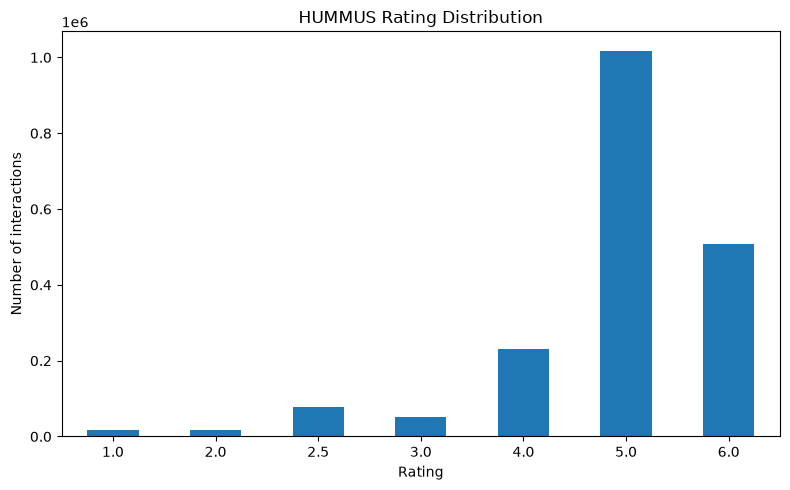

In [34]:
if "rating" in reviews.columns:
    plt.figure(figsize=(8, 5))
    
    reviews["rating"].value_counts().sort_index().plot(
        kind="bar"
    )
    
    plt.xlabel("Rating")
    plt.ylabel("Number of interactions")
    plt.title("HUMMUS Rating Distribution")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

#### Special HUMMUS rating values

In [35]:
if "rating" in reviews.columns:
    print("Ratings below 1 or above 5:")
    
    unusual_ratings = reviews[
        (reviews["rating"] < 1) |
        (reviews["rating"] > 5)
    ]
    
    print(f"Count: {len(unusual_ratings):,}")
    
    display(
        unusual_ratings["rating"]
        .value_counts()
        .sort_index()
    )

Ratings below 1 or above 5:
Count: 506,510


rating
6.0    506510
Name: count, dtype: int64

In [36]:
if "rating" in reviews.columns:
    print("Potential special preprocessing values:")
    
    for value in [0, 2.5, 6]:
        count = (reviews["rating"] == value).sum()
        print(f"Rating {value}: {count:,}")

Potential special preprocessing values:
Rating 0: 0
Rating 2.5: 76,876
Rating 6: 506,510


#### Review text audit

In [38]:
# Find likely text columns

text_columns = [
    col for col in reviews.columns
    if reviews[col].dtype == "str"
]

print("Text/object columns:")
print(text_columns)

Text/object columns:
['text', 'last_modified_date', 'review_url', 'member_url']


#### Review text length

In [39]:
if "text" in reviews.columns:
    
    reviews["review_text_length"] = (
        reviews["text"]
        .fillna("")
        .astype(str)
        .str.len()
    )
    
    reviews["review_word_count"] = (
        reviews["text"]
        .fillna("")
        .astype(str)
        .str.split()
        .str.len()
    )
    
    display(
        reviews[
            ["review_text_length", "review_word_count"]
        ].describe()
    )

,review_text_length,review_word_count
count,1.916424e+06,1.916424e+06
mean,2.025118e+02,3.786160e+01
std,2.074602e+02,3.896334e+01
min,0.000000e+00,0.000000e+00
25%,0.000000e+00,0.000000e+00
50%,1.700000e+02,3.100000e+01
75%,3.030000e+02,5.700000e+01
max,8.587000e+03,1.182000e+03


In [40]:
if "text" in reviews.columns:
    
    reviews["review_text_length"] = (
        reviews["text"]
        .fillna("")
        .astype(str)
        .str.len()
    )
    
    reviews["review_word_count"] = (
        reviews["text"]
        .fillna("")
        .astype(str)
        .str.split()
        .str.len()
    )
    
    display(
        reviews[
            ["review_text_length", "review_word_count"]
        ].describe()
    )

,review_text_length,review_word_count
count,1.916424e+06,1.916424e+06
mean,2.025118e+02,3.786160e+01
std,2.074602e+02,3.896334e+01
min,0.000000e+00,0.000000e+00
25%,0.000000e+00,0.000000e+00
50%,1.700000e+02,3.100000e+01
75%,3.030000e+02,5.700000e+01
max,8.587000e+03,1.182000e+03


#### Temporal audit

In [41]:
date_columns = [
    col for col in reviews.columns
    if any(
        keyword in col.lower()
        for keyword in ["date", "time", "submit", "changed", "modified"]
    )
]

print("Potential date columns:")
print(date_columns)

Potential date columns:
['last_modified_date']


In [42]:
for col in date_columns:
    reviews[col] = pd.to_datetime(
        reviews[col],
        errors="coerce"
    )

    print("=" * 70)
    print(col)
    print("=" * 70)
    print("Valid dates:", reviews[col].notna().sum())
    print("Missing dates:", reviews[col].isna().sum())
    
    if reviews[col].notna().any():
        print("Minimum:", reviews[col].min())
        print("Maximum:", reviews[col].max())

last_modified_date
Valid dates: 1916424
Missing dates: 0
Minimum: 2000-01-25 00:00:00
Maximum: 2022-09-19 00:00:00


### User interaction-history audit

In [43]:
user_interactions = (
    reviews
    .groupby("new_member_id")
    .size()
    .rename("interaction_count")
    .sort_values(ascending=False)
)

display(user_interactions.describe())

count    302412.000000
mean          6.337129
std          72.795405
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max        9906.000000
Name: interaction_count, dtype: float64

### User history thresholds

In [45]:
thresholds = [1, 2, 3, 5, 10, 20, 30, 50, 100]

threshold_results = []

for threshold in thresholds:
    count = (user_interactions >= threshold).sum()
    
    threshold_results.append({
        "minimum_interactions": threshold,
        "eligible_users": count,
        "percentage_of_users": (
            count / len(user_interactions) * 100
        )
    })

history_thresholds = pd.DataFrame(threshold_results)

display(history_thresholds)

,minimum_interactions,eligible_users,percentage_of_users
0,1,302412,100.000000
1,2,86426,28.578892
2,3,54858,18.140153
3,5,34133,11.286920
4,10,19016,6.288110
5,20,10497,3.471092
6,30,7414,2.451622
7,50,4614,1.525733
8,100,2376,0.785683


### Reviews per recipe

In [47]:
recipe_interactions = (
    reviews
    .groupby("new_recipe_id")
    .size()
    .rename("interaction_count")
    .sort_values(ascending=False)
)

display(recipe_interactions)

new_recipe_id
205530    2910
241570    2207
373713    1621
94958     1588
378770    1506
          ... 
507324       1
507323       1
507321       1
507318       1
18           1
Name: interaction_count, Length: 507335, dtype: int64

### User rating behavior

In [49]:
if "rating" in reviews.columns:
    
    user_rating_stats = (
        reviews
        .groupby("new_member_id")["rating"]
        .agg(
            interaction_count="count",
            mean_rating="mean",
            median_rating="median",
            rating_std="std"
        )
    )
    
    display(user_rating_stats)

,interaction_count,mean_rating,median_rating,rating_std
new_member_id,,,,
0,64,5.078125,5.0,0.513460
1,118,4.504237,5.0,1.283518
2,3,4.666667,5.0,0.577350
3,1,5.000000,5.0,NaN
4,2473,4.901739,5.0,0.477708
...,...,...,...,...
302407,1,6.000000,6.0,NaN
302408,1,6.000000,6.0,NaN
302409,1,6.000000,6.0,NaN


### High-rated vs low-rated interactions

In [50]:
if "rating" in reviews.columns:
    
    rating_categories = pd.cut(
        reviews["rating"],
        bins=[-np.inf, 2, 3, 4, np.inf],
        labels=[
            "Low (<=2)",
            "Medium (>2 to 3)",
            "Good (>3 to 4)",
            "High (>4)"
        ]
    )
    
    display(
        rating_categories
        .value_counts()
        .sort_index()
    )

rating
Low (<=2)             34697
Medium (>2 to 3)     127440
Good (>3 to 4)       229869
High (>4)           1524418
Name: count, dtype: int64

### User–recipe-review join integrity

In [51]:
# Users appearing in reviews
review_users = set(
    reviews["new_member_id"].dropna().unique()
)

member_ids = set(
    members["new_member_id"].dropna().unique()
)

# Recipes appearing in reviews
review_recipes = set(
    reviews["new_recipe_id"].dropna().unique()
)

recipe_ids = set(
    recipes["new_recipe_id"].dropna().unique()
)

missing_users = review_users - member_ids
missing_recipes = review_recipes - recipe_ids

print("User-recipe join integrity")
print("=" * 70)

print(
    f"Review users not found in members: "
    f"{len(missing_users):,}"
)

print(
    f"Review recipes not found in recipes: "
    f"{len(missing_recipes):,}"
)

User-recipe join integrity
Review users not found in members: 2,829
Review recipes not found in recipes: 0


### Percentage of invalid interactions

In [52]:
valid_user = reviews["new_member_id"].isin(member_ids)
valid_recipe = reviews["new_recipe_id"].isin(recipe_ids)

valid_both = valid_user & valid_recipe

print(
    f"Reviews with valid user: "
    f"{valid_user.mean() * 100:.4f}%"
)

print(
    f"Reviews with valid recipe: "
    f"{valid_recipe.mean() * 100:.4f}%"
)

print(
    f"Reviews with valid user AND recipe: "
    f"{valid_both.mean() * 100:.4f}%"
)

Reviews with valid user: 99.3104%
Reviews with valid recipe: 100.0000%
Reviews with valid user AND recipe: 99.3104%


### Duplicate user-recipe interactions

In [53]:
user_recipe_duplicates = (
    reviews
    .groupby(["new_member_id", "new_recipe_id"])
    .size()
    .sort_values(ascending=False)
)

print(
    "User-recipe pairs with more than one interaction:",
    (user_recipe_duplicates > 1).sum()
)

display(
    user_recipe_duplicates[
        user_recipe_duplicates > 1
    ].head(20)
)

User-recipe pairs with more than one interaction: 0


Series([], dtype: int64)

### Interaction matrix sparsity

In [54]:
num_users = reviews["new_member_id"].nunique()
num_recipes = reviews["new_recipe_id"].nunique()
num_interactions = len(reviews)

total_possible = num_users * num_recipes

sparsity = 1 - (
    num_interactions / total_possible
)

density = (
    num_interactions / total_possible
)

print(f"Unique users:        {num_users:,}")
print(f"Unique recipes:      {num_recipes:,}")
print(f"Interactions:        {num_interactions:,}")
print(f"Possible interactions: {total_possible:,}")
print(f"Interaction density: {density:.8%}")
print(f"Interaction sparsity: {sparsity:.8%}")

Unique users:        302,412
Unique recipes:      507,335
Interactions:        1,916,424
Possible interactions: 153,424,192,020
Interaction density: 0.00124910%
Interaction sparsity: 99.99875090%


### Historical profile candidate analysis

In [55]:
# Select useful recipe attributes
recipe_evidence_columns = [
    "new_recipe_id",
    "title",
    "tags",
    "ingredients_sizes",
    "duration",
    "calories [cal]",
    "protein [g]",
    "totalFat [g]",
    "sugars [g]",
    "sodium [mg]",
    "dietaryFiber [g]",
    "nutri_score"
]

available_evidence_columns = [
    col for col in recipe_evidence_columns
    if col in recipes.columns
]

review_recipe = reviews.merge(
    recipes[available_evidence_columns],
    on="new_recipe_id",
    how="left",
    suffixes=("_review", "_recipe")
)

print("Joined review-recipe dataset:")
print(review_recipe.shape)

display(review_recipe.head())

Joined review-recipe dataset:
(1916424, 25)


,Unnamed: 0,member_id,recipe_id,rating,text,likes,last_modified_date,review_id,review_url,member_url,new_member_id,new_recipe_id,review_text_length,review_word_count,title,tags,ingredients_sizes,duration,calories [cal],protein [g],totalFat [g],sugars [g],sodium [mg],dietaryFiber [g],nutri_score
0,0,192799,96347,5.0,"I've never made ham & beans before, but I've a...",0.0,2005-05-02,171462.0,https://www.food.com/recipe/crock-pot-ham-and-...,https://www.food.com/user/192799,0,274797,487,91,Crock Pot Ham and Beans,"['ham', 'time-to-make', 'course', 'main-ingred...",9,540.0,636.1,51.7,14.6,4.2,2281.1,23.8,0.25
1,1,394617,37139,2.5,Great curry. Will make again. I was thinking...,0.0,2012-03-25,1296592.0,https://www.food.com/recipe/curry-chicken-with...,https://www.food.com/user/394617,1,274880,73,14,Curry Chicken with Coconut and Peanuts,"['curries', '60-minutes-or-less', 'time-to-mak...",15,60.0,370.4,35.8,20.0,2.2,223.8,2.1,0.25
2,2,170674,37139,5.0,This was really good even my picky kid loved i...,0.0,2011-10-03,1254955.0,https://www.food.com/recipe/curry-chicken-with...,https://www.food.com/user/170674,2,274880,207,40,Curry Chicken with Coconut and Peanuts,"['curries', '60-minutes-or-less', 'time-to-mak...",15,60.0,370.4,35.8,20.0,2.2,223.8,2.1,0.25
3,3,1800369,37139,5.0,I used chicken base instead of beef bullion an...,0.0,2011-01-20,1184045.0,https://www.food.com/recipe/curry-chicken-with...,https://www.food.com/user/1800369,3,274880,247,44,Curry Chicken with Coconut and Peanuts,"['curries', '60-minutes-or-less', 'time-to-mak...",15,60.0,370.4,35.8,20.0,2.2,223.8,2.1,0.25
4,4,126440,37139,5.0,I made half a recipe and it was just right for...,0.0,2010-12-24,1174963.0,https://www.food.com/recipe/curry-chicken-with...,https://www.food.com/user/126440,4,274880,135,27,Curry Chicken with Coconut and Peanuts,"['curries', '60-minutes-or-less', 'time-to-mak...",15,60.0,370.4,35.8,20.0,2.2,223.8,2.1,0.25


In [56]:
evidence_stats = (
    review_recipe
    .groupby("new_member_id")
    .agg(
        interaction_count=("new_recipe_id", "count"),
        rated_interactions=("rating", lambda x: (x > 0).sum()),
        review_text_count=(
            "text",
            lambda x: x.notna().sum()
            if "text" in review_recipe.columns
            else 0
        )
    )
)

display(evidence_stats.describe())

,interaction_count,rated_interactions,review_text_count
count,302412.000000,302412.000000,302412.000000
mean,6.337129,6.337129,4.661541
std,72.795405,72.795405,50.797143
min,1.000000,1.000000,0.000000
25%,1.000000,1.000000,1.000000
50%,1.000000,1.000000,1.000000
75%,2.000000,2.000000,1.000000
max,9906.000000,9906.000000,8844.000000


In [57]:
# Example thresholds for inspection only.
# We will decide the final threshold after seeing the results.

candidate_thresholds = [3, 5, 10, 20]

profile_candidates = []

for threshold in candidate_thresholds:
    
    eligible = evidence_stats[
        evidence_stats["interaction_count"] >= threshold
    ]
    
    profile_candidates.append({
        "minimum_interactions": threshold,
        "eligible_users": len(eligible),
        "percent_users": (
            len(eligible) / len(evidence_stats) * 100
        ),
        "median_interactions": (
            eligible["interaction_count"].median()
            if len(eligible) > 0
            else np.nan
        )
    })

profile_candidates = pd.DataFrame(profile_candidates)

display(profile_candidates)

,minimum_interactions,eligible_users,percent_users,median_interactions
0,3,54858,18.140153,6.0
1,5,34133,11.286920,11.0
2,10,19016,6.288110,22.0
3,20,10497,3.471092,43.0


### Top recipes by interaction count

In [58]:
top_recipes = (
    reviews
    .groupby("new_recipe_id")
    .size()
    .sort_values(ascending=False)
    .head(20)
    .rename("interaction_count")
    .reset_index()
)

if "title" in recipes.columns:
    top_recipes = top_recipes.merge(
        recipes[["new_recipe_id", "title"]],
        on="new_recipe_id",
        how="left"
    )

display(top_recipes)

,new_recipe_id,interaction_count,title
0,205530,2910,Bourbon Chicken
1,241570,2207,Best Banana Bread
2,373713,1621,To Die for Crock Pot Roast
3,94958,1588,Crock-Pot Chicken With Black Beans & Cream Cheese
4,378770,1506,Creamy Cajun Chicken Pasta
5,492546,1375,Best Ever Banana Cake With Cream Cheese Frosting
6,188825,1364,Oatmeal Raisin Cookies
7,433221,1341,"Yes, Virginia There is a Great Meatloaf"
8,331526,1297,Jo Mama's World Famous Spaghetti
9,34821,1232,"""Whatever Floats Your Boat"" Brownies!"


### Top users by interaction count

In [59]:
top_users = (
    reviews
    .groupby("new_member_id")
    .size()
    .sort_values(ascending=False)
    .head(20)
    .rename("interaction_count")
    .reset_index()
)

display(top_users)

,new_member_id,interaction_count
0,612,9906
1,53,9850
2,105,8933
3,71,7889
4,1372,6913
5,115,6357
6,677,6206
7,152,5685
8,333,5453
9,842,5230
